78
88
EOS 0 done
EOS 1 done
EOS 2 done
EOS 3 done
EOS 4 done
EOS 5 done
EOS 6 done
EOS 7 done
EOS 8 done
EOS 9 done


<>:79: SyntaxWarning: invalid escape sequence '\e'
<>:83: SyntaxWarning: invalid escape sequence '\m'
<>:86: SyntaxWarning: invalid escape sequence '\e'
<>:115: SyntaxWarning: invalid escape sequence '\o'
<>:79: SyntaxWarning: invalid escape sequence '\e'
<>:83: SyntaxWarning: invalid escape sequence '\m'
<>:86: SyntaxWarning: invalid escape sequence '\e'
<>:115: SyntaxWarning: invalid escape sequence '\o'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_9256/2871431346.py:79: SyntaxWarning: invalid escape sequence '\e'
  ax[0].set_ylabel("$\epsilon$  $(MeV/fm^{3})$")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_9256/2871431346.py:83: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_xlabel("$\mu$ ($MeV$)")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_9256/2871431346.py:86: SyntaxWarning: invalid escape sequence '\e'
  ax[2].set_xlabel("$\epsilon$  $(MeV/fm^{3})$")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_9256/2871431346.py:

(1.0, 100.0)

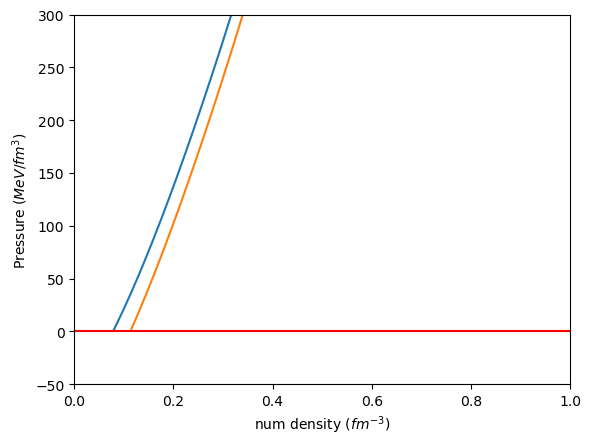

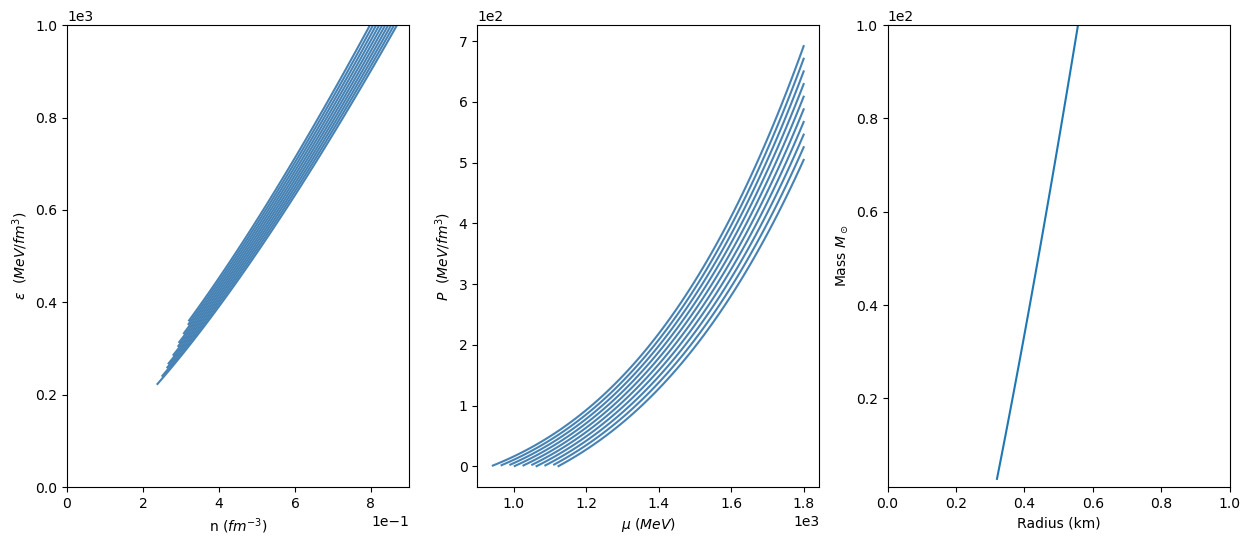

In [2]:
#                MIT Bag Model
import numpy as np
import matplotlib.pyplot as plt
from numba import jit

#hbar_c_in_GeV_fm = 0.1973
hbar_c_in_GeV_fm = 1
mu_arr = np.linspace(0,1.8,150)

@jit(nopython = True)
def Thermo_potential(mu_arr, alpha_s):
    re = -(((mu_arr**4)/(4*(np.pi**2))) * (1 - (2*alpha_s/np.pi)))/((hbar_c_in_GeV_fm)**3)
    return re

#@jit(nopython = True)
def Bag_results(mu_arr, alpha_s, B):
    potential = Thermo_potential(mu_arr, alpha_s)
    num_arr = -1*np.gradient(potential, mu_arr)
    ene_arr = np.array([3*(pot*1000 + mu*n*1000) + B for pot,mu,n in zip(potential, mu_arr, num_arr)])          ########  3 is multiplied for 3 quark flavors: u,d,s
    pre_arr = np.array([-3*(pot*1000) - B for pot in potential])
    return ene_arr, pre_arr, num_arr

#%%
# Testing the functions
B = np.array([55,90])
alpha = np.array([0.1,0.2])

for i in range(len(B)):
    ene_arr, pre_arr, num_arr = Bag_results(mu_arr, 0.1,B[i])
    index = np.argmax(pre_arr> 0)
    print(index)
    plt.plot(num_arr[index:], pre_arr[index:])
plt.xlim([0,1])
plt.ylim([-50,300])
plt.axhline(y=0, color='r', linestyle='-')
plt.xlabel("num density $(fm^{-3})$")
plt.ylabel("Pressure $(MeV/fm^{3})$")
#%%
def get_pre_ene_num_mu(mu_arr, alpha_s, B):
    ene_arr, pre_arr, num_arr = Bag_results(mu_arr, alpha_s,B)
    index = np.argmax(pre_arr> 0)
    ene = ene_arr[index:]
    pre = pre_arr[index:]
    num = 3*num_arr[index:]
    mu  = mu_arr[index:]
    return pre, ene, num, mu
#%%
from matplotlib.ticker import ScalarFormatter
alpha_arr = np.linspace(0.1,0.4,10)
B_arr = np.linspace(55,90,10)
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15,6))

for i in range(len(alpha_arr)):
    al = alpha_arr[i]
    b = B_arr[i]
    q_pre, q_ene, q_num, q_mu = get_pre_ene_num_mu(mu_arr, al, b)
    
    headers = "Pressure                   Energy density            number density            chemical potential"
    headers_params = "alpha                               B(MeV/fm^3)"
    
    stacked_data = np.column_stack((q_pre, q_ene, q_num, q_mu*1000))
    stacked_params = np.column_stack((al, b))
    
    np.savetxt(f"EOS_bag_{i}.dat", stacked_data, header=headers)
    np.savetxt(f"EOS_bag_params_{i}.dat", stacked_params, header=headers_params, delimiter="      ")

    ax[0].plot(q_num, q_ene, color = "steelblue")
    ax[0].ticklabel_format(style='sci', axis='both', scilimits=(0,0))
    #ax[0].xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    
    ax[1].plot(q_mu*1000, q_pre, color = "steelblue")
    ax[1].ticklabel_format(style='sci', axis='both', scilimits=(0,0))
    #ax[1].xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    
    ax[2].plot(q_ene, q_pre, color = "steelblue") 
    ax[2].ticklabel_format(style='sci', axis='both', scilimits=(0,0))
#ax[2].xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax[0].set_xlabel("n ($fm^{-3}$)")
ax[0].set_ylabel("$\epsilon$  $(MeV/fm^{3})$")
ax[0].set_xlim([0,0.9])
ax[0].set_ylim([0,1000])

ax[1].set_xlabel("$\mu$ ($MeV$)")
ax[1].set_ylabel("$P$  $(MeV/fm^{3})$")

ax[2].set_xlabel("$\epsilon$  $(MeV/fm^{3})$")
ax[2].set_ylabel("$P$  $(MeV/fm^{3})$")

#%%
import TOV_module

for i in range(10):
    bag_model_dat = np.loadtxt(f"EOS_bag_{i}.dat")
    pre_dat = bag_model_dat[:,0]
    ene_dat = bag_model_dat[:,1]
    num_dat = bag_model_dat[:,2]
    
    G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
    c1 = 3*10**(8)                  ############ m / s
    
    Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4
    
    pre_gu = pre_dat*Mev_fm3_to_GU
    ene_gu = ene_dat*Mev_fm3_to_GU
    
    
    ene_dens = np.logspace(np.log10(max(ene_gu)*0.99), np.log10(min(ene_gu)*1.01), 100)
    #M,R = TOV_module.TOV_M_R(ene_dens, pre_gu, ene_gu, min(pre_gu), to_print=False)
    
    #ind  = np.argmax(M)
    #plt.plot(R[ind:],M[ind:])
    print(f"EOS {i} done", flush=True)

plt.xlabel("Radius (km)")
plt.ylabel("Mass $M_\odot$")
#%%
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
n0    = 0.15
n_b = [0.165, 0.316, 0.53, 0.85]
K_b = [17906.60, 1, 302.56]
Gam_b = [4.92, 0, 2.50]
m0 = [939.56, 939.56,  991.75]


@jit(nopython=True)
def P_from_nb(n_list, K, Gam):
    res = K*(n_list)**(Gam)
    return res

@jit(nopython=True)
def mu_from_n(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list/n0)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

n1_b = np.linspace(n_b[0], n_b[1], 100)
P1_b = P_from_nb(n1_b, K_b[0], Gam_b[0])
mu1_b = mu_from_nb(n1_b, K_b[0], Gam_b[0], m0[0])
e1_b = [-p + n*u for p,n,u in zip(P1_b, n1_b, mu1_b)]

#%%
quark_bag_dat = np.loadtxt("EOS_bag_8.dat")
quark_bag_pre = quark_bag_dat[:,0]
quark_bag_ene = quark_bag_dat[:,1]
quark_bag_num = quark_bag_dat[:,2]
quark_bag_mu = quark_bag_dat[:,3]

# plt.plot(mu1_b,P1_b)
plt.plot(quark_bag_num, quark_bag_pre)
plt.xlim([0,1])
plt.ylim([1,100])

